# Worked example: archetype 2, y direction

This notebook carries one suspended piping system through the reduced-order procedure of the paper, step by
step and with actual numbers: Phase 1 (equivalent single-pipeline model, Section 3.1) and Phase 2 (equivalent
SDOF system, Section 3.2). Step and equation numbers refer to the paper.

The system is archetype 2 loaded in the y direction (`inputs/archetypes/M02y.yaml`), the same system as in the
paper's force-displacement, displaced-shape and fragility comparisons. Every quantity is computed explicitly
with NumPy from the inputs; where `piperom` computes the same quantity, the notebook checks that both agree.
The only step left to a finite-element solver is the linear static analysis of the beam on springs (step 3e).

The same example, written out with its tables, is in
[`worked_example_archetype2_y.md`](worked_example_archetype2_y.md).

Units: N, mm, s; masses in tonnes (t), also given in kg/m per unit length.

Run from the repository root or from `examples/` with the environment of the README (Python 3.12,
`pip install -r requirements.txt`). No floor motions are needed.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(REPO))

from piperom.inputs import load_settings, load_system
from piperom.pushover import solver_settings
from piperom.static_model import _section, normalize_shape, solve_static_step

rs = load_system(REPO / "inputs" / "archetypes" / "M02y.yaml").resolve()
settings = load_settings()               # defaults of inputs/defaults/settings.yaml
solver = solver_settings(settings)

DELTA_C = 12.0                           # target displacement (mm), Section 3.1 step 3
TOL = settings.tolerance                 # convergence tolerance of the shape iteration
pd.set_option("display.precision", 4)

## 0. Input data

**Geometry.** One main line, 36 m long, made of three parallel 127/113 mm water-filled steel pipes, on gravity
hangers every 3 m starting 1 m from its left end. Four of the hangers carry transverse seismic restraints. In the
y direction the main line is the transverse pipeline; the 18 m branch that frames into its right end (x = 36 m)
runs parallel to the excitation, so it is the longitudinal pipeline, with two longitudinal restraints.

In [2]:
geometry = pd.DataFrame({
    "x (m)": np.r_[rs.hanger_x, rs.branch_x] / 1000,
    "point": ["hanger"] * rs.n_hangers + ["junction with longitudinal line"],
    "seismic restraint": ["transverse" if b else "-" for b in rs.brace_mask] + [f"{rs.branch_n_braces[0]} longitudinal (on the branch)"],
})
geometry.index.name = "DOF"
print(f"Transverse pipeline: L = {rs.length / 1000:g} m, {rs.n_pipes} pipes")
print(f"Longitudinal pipeline: L = {rs.branch_length[0] / 1000:g} m, {rs.branch_n_pipes[0]} pipes, at x = {rs.branch_x[0] / 1000:g} m")
geometry

Transverse pipeline: L = 36 m, 3 pipes
Longitudinal pipeline: L = 18 m, 3 pipes, at x = 36 m


,x (m),point,seismic restraint
DOF,,,
0,1.0,hanger,transverse
1,4.0,hanger,-
2,7.0,hanger,-
3,10.0,hanger,-
4,13.0,hanger,transverse
5,16.0,hanger,-
6,19.0,hanger,-
7,22.0,hanger,transverse
8,25.0,hanger,-


**Section and mass per unit length.** Steel and contained water of the three pipes, increased by 35% to account
for fittings and the weight of the trapezes, a standard allowance in similar studies (`pipe.mass_factor` = 1.35 in
`inputs/defaults/system.yaml`).

In [3]:
p = rs.pipe
A, Aw, J, I = _section(rs.n_pipes, p.outer_diameter, p.inner_diameter)     # 3 pipes
m_steel = p.density * A                     # t/mm
m_water = p.effective_fluid_density * Aw    # t/mm (water density = steel density / 7.8)
m_line = p.mass_factor * (m_steel + m_water)
section = pd.Series({
    "A, steel (mm2)": A, "I (mm4)": I, "E (MPa)": p.elastic_modulus,
    "steel (kg/m)": m_steel * 1e6, "water (kg/m)": m_water * 1e6,
    "mass factor": p.mass_factor, "m per unit length (kg/m)": m_line * 1e6,
})
section.to_frame("value")

,value
"A, steel (mm2)",7.9168e+03
I (mm4),1.4299e+07
E (MPa),2.1000e+05
steel (kg/m),6.2147e+01
water (kg/m),3.0279e+01
mass factor,1.3500e+00
m per unit length (kg/m),1.2478e+02


**Seismic restraints.** The equivalent static procedure uses a trilinear backbone of each restraint, taken from
the envelope of its Pinching4 model (`inputs/trapezes/`): elastic up to the first yield point
$(d_1, F_1)$, then to $(d_2, F_2)$, then a post-yield slope of 1% of the elastic one.

In [4]:
tri_T, tri_L = rs.transverse_trilinear, rs.longitudinal_trilinear
pd.DataFrame(
    [[t.d1, t.f1, t.d2, t.f2, t.k1, t.k3_ratio] for t in (tri_T, tri_L)],
    index=["transverse restraint", "longitudinal restraint"],
    columns=["d1 (mm)", "F1 (N)", "d2 (mm)", "F2 (N)", "k1 (N/mm)", "post-yield ratio"])

,d1 (mm),F1 (N),d2 (mm),F2 (N),k1 (N/mm),post-yield ratio
transverse restraint,10.0,6000.0,17.0,9000.0,600.0,0.01
longitudinal restraint,12.0,7500.0,24.0,10000.0,625.0,0.01


## Phase 1: equivalent single-pipeline model (Section 3.1)

### Step 1: lump the longitudinal line into one mass-spring system

The branch moves almost rigidly along its axis, so it becomes one mass, its total mass $m_{L,1}$, on one
spring, the two longitudinal restraints in parallel ($k_{L,1}$: forces of one restraint times two).

In [5]:
A_b, Aw_b, _, _ = _section(int(rs.branch_n_pipes[0]), p.outer_diameter, p.inner_diameter)
m_line_b = p.mass_factor * (p.density * A_b + p.effective_fluid_density * Aw_b)
n_L = int(rs.branch_n_braces[0])
m_L = rs.branch_participation * m_line_b * rs.branch_length[0]
print(f"m_L,1 = {m_line_b * 1e6:.2f} kg/m x {rs.branch_length[0] / 1000:g} m = {m_L:.4f} t")
print(f"k_L,1 backbone: {n_L} x longitudinal restraint -> "
      f"({tri_L.d1:g} mm, {n_L * tri_L.f1:g} N), ({tri_L.d2:g} mm, {n_L * tri_L.f2:g} N)")

m_L,1 = 124.78 kg/m x 18 m = 2.2460 t
k_L,1 backbone: 2 x longitudinal restraint -> (12 mm, 15000 N), (24 mm, 20000 N)


### Step 2: conceptual idealisations

**2.1 Segments.** The only longitudinal line frames into the right end of the transverse line, so the
transverse line is a single segment, $t = 1$, from x = 0 to x = 36 m.

**2.2 Masses.** The pipe mass is lumped at the hangers (braced or not) and at the junction with the
longitudinal line, using half the distance to the neighbouring points. The tributary mass of the transverse
line carried by the longitudinal line, $m_{T|L,1}$, is the mass within half the distance to the nearest support
(the transverse restraint at 34 m), i.e. from 35 m to 36 m.

The first 0.5 m at the free left end lumps onto the end node, which is not a DOF of the procedure (no hanger
there), so it does not take part in it (0.06 t, under 1% of the mass).

In [6]:
x_mass = np.unique(np.r_[0.0, rs.hanger_x, rs.branch_x, rs.length])     # points that receive mass
trib = 0.5 * (np.r_[0.0, np.diff(x_mass)] + np.r_[np.diff(x_mass), 0.0])  # tributary lengths
mass_at = dict(zip(x_mass, trib * m_line))

x_dof = np.r_[rs.hanger_x, rs.branch_x]
m_dof = np.array([mass_at[x] for x in x_dof])         # m_T,s,1 at the hangers; m_T|L,1 at the junction
m_TL = m_dof[-1]
idx_T = np.where(rs.brace_mask == 1)[0]               # DOFs with a transverse restraint

masses = pd.DataFrame({
    "x (m)": x_dof / 1000, "tributary length (m)": [trib[np.searchsorted(x_mass, x)] / 1000 for x in x_dof],
    "mass (t)": m_dof,
    "symbol": [f"m_T,{s},1" for s in range(1, rs.n_hangers + 1)] + ["m_T|L,1"],
})
masses.index.name = "DOF"
m_end = mass_at[0.0]
m_total = m_dof.sum() + m_L
print(f"m_T|L,1 = {m_TL:.4f} t;  m_L,1 = {m_L:.4f} t;  end node (not a DOF) = {m_end:.4f} t")
print(f"Total mass in the procedure: {m_dof.sum():.4f} (transverse line) + {m_L:.4f} (longitudinal line) = {m_total:.4f} t")
masses

m_T|L,1 = 0.1248 t;  m_L,1 = 2.2460 t;  end node (not a DOF) = 0.0624 t
Total mass in the procedure: 4.4295 (transverse line) + 2.2460 (longitudinal line) = 6.6755 t


,x (m),tributary length (m),mass (t),symbol
DOF,,,,
0,1.0,2.0,0.2496,"m_T,1,1"
1,4.0,3.0,0.3743,"m_T,2,1"
2,7.0,3.0,0.3743,"m_T,3,1"
3,10.0,3.0,0.3743,"m_T,4,1"
4,13.0,3.0,0.3743,"m_T,5,1"
5,16.0,3.0,0.3743,"m_T,6,1"
6,19.0,3.0,0.3743,"m_T,7,1"
7,22.0,3.0,0.3743,"m_T,8,1"
8,25.0,3.0,0.3743,"m_T,9,1"


**2.3 Parallel transverse lines.** Not needed here: in the y direction there is only one transverse line.

### Step 3: equivalent linear static analysis

The displaced shape $\Delta$ is iterated at a fixed target displacement $\Delta_c$ = 12 mm, assigned to the largest
displacement of the transverse line (the shape is normalised to a maximum of 1 and scaled by $\Delta_c$). With this
target, the most-displaced transverse restraint reaches approximately its first-yield displacement (10 mm). The
initial guess (step a) is a vector of ones, and the displacement of the lumped longitudinal mass equals that of the
junction, $\Delta_{L,1} = \Delta_{T|L,1}$.

The function below performs steps b to d for a given $\Delta$, with the equation numbers of the paper.

In [7]:
def load_pattern(Delta):
    # b) reactions of the restraints from their backbones at Delta, and secant stiffnesses
    F_T = np.array([tri_T.force(Delta[i]) for i in idx_T])
    k_T = F_T / Delta[idx_T]
    V_T_tot = F_T.sum()                                    # V_T,tot,1
    V_L_tot = n_L * tri_L.force(Delta[-1])                 # V_L,tot,1
    # c) transfer between the lines, by tributary mass (Eqs. 3-5); gamma = 1: the junction is at the
    #    right end, so all of m_T|L,1 belongs to segment 1
    V_L = m_L / (m_L + m_TL) * V_L_tot                     # Eq. 3: stays on the longitudinal line
    V_TL = 1.0 * m_TL / (m_L + m_TL) * V_L_tot             # Eq. 4: passed to segment 1
    # d) total force on segment 1 (Eq. 6), distributed in proportion to m * Delta (Eqs. 7-8)
    V_tot = V_T_tot + V_TL
    F = m_dof * Delta / np.sum(m_dof * Delta) * V_tot
    return dict(F_T=F_T, k_T=k_T, V_T_tot=V_T_tot, V_L_tot=V_L_tot, V_L=V_L, V_TL=V_TL, V_tot=V_tot, F=F)

**Iteration 1 in detail.** With $\Delta$ = 12 mm everywhere:

In [8]:
d = np.ones(rs.n_dof)
lp = load_pattern(DELTA_C * d)
print(f"b) each transverse restraint at 12 mm: F = {lp['F_T'][0]:.1f} N, secant k = {lp['k_T'][0]:.1f} N/mm")
print(f"   V_T,tot,1 = 4 x {lp['F_T'][0]:.1f} = {lp['V_T_tot']:.1f} N;  V_L,tot,1 = {n_L} x {tri_L.force(DELTA_C):.1f} = {lp['V_L_tot']:.1f} N")
print(f"c) Eq. 3: V_L,1 = {m_L:.4f}/({m_L:.4f} + {m_TL:.4f}) x {lp['V_L_tot']:.1f} = {lp['V_L']:.1f} N")
print(f"   Eq. 4: V_T|L,1,1 = {m_TL:.4f}/({m_L:.4f} + {m_TL:.4f}) x {lp['V_L_tot']:.1f} = {lp['V_TL']:.1f} N")
print(f"d) Eq. 6: V_tot,1 = {lp['V_T_tot']:.1f} + {lp['V_TL']:.1f} = {lp['V_tot']:.1f} N, distributed by m x Delta (Eqs. 7-8):")
pd.DataFrame({"x (m)": x_dof / 1000, "m (t)": m_dof, "Delta (mm)": DELTA_C * d, "F (N)": lp["F"]})

b) each transverse restraint at 12 mm: F = 6857.1 N, secant k = 571.4 N/mm
   V_T,tot,1 = 4 x 6857.1 = 27428.6 N;  V_L,tot,1 = 2 x 7500.0 = 15000.0 N
c) Eq. 3: V_L,1 = 2.2460/(2.2460 + 0.1248) x 15000.0 = 14210.5 N
   Eq. 4: V_T|L,1,1 = 0.1248/(2.2460 + 0.1248) x 15000.0 = 789.5 N
d) Eq. 6: V_tot,1 = 27428.6 + 789.5 = 28218.0 N, distributed by m x Delta (Eqs. 7-8):


,x (m),m (t),Delta (mm),F (N)
0,1.0,0.2496,12.0,1589.7490
1,4.0,0.3743,12.0,2384.6235
2,7.0,0.3743,12.0,2384.6235
3,10.0,0.3743,12.0,2384.6235
4,13.0,0.3743,12.0,2384.6235
5,16.0,0.3743,12.0,2384.6235
6,19.0,0.3743,12.0,2384.6235
7,22.0,0.3743,12.0,2384.6235
8,25.0,0.3743,12.0,2384.6235
9,28.0,0.3743,12.0,2384.6235


**e) Linear static analysis.** The forces are applied to a linear model of the transverse line: an elastic beam
($EI$ of the three pipes) on the transverse restraints, each a spring with the secant stiffness of step b (the
unbraced hangers carry no lateral load), and a rigid link to the lumped longitudinal mass on its spring, loaded by
$V_{L,1}$. `solve_static_step` builds and solves this model in OpenSees; the check below confirms that the
forces it applies are those computed above. The solution $\Delta'$ is normalised to a maximum of 1 and compared
with the previous shape through the RMS change per DOF.

In [9]:
step = solve_static_step(rs, d, DELTA_C, solver)
assert np.allclose(step.loads, lp["F"]) and np.isclose(step.branch_stay_load[0], lp["V_L"])
assert np.allclose(step.brace_stiffness, lp["k_T"])
d_new = normalize_shape(step.u)
print("Delta' (mm):", np.round(step.u, 3))
print("normalised :", np.round(d_new, 4))
print(f"RMS change = {np.linalg.norm(d_new - d) / np.sqrt(rs.n_dof):.4f}")

Delta' (mm): [10.565 13.922 15.487 15.243 13.207 15.053 15.107 13.37  15.584 16.006
 14.621 11.443 11.733]
normalised : [0.6601 0.8698 0.9675 0.9523 0.8251 0.9404 0.9438 0.8353 0.9736 1.
 0.9134 0.7149 0.733 ]
RMS change = 0.1666


**Iterations to convergence.** Steps b to e are repeated with $\Delta = \Delta_c\,\Delta'/\max|\Delta'|$ until the RMS
change of the normalised shape is below the tolerance (`shape_iteration.tolerance` = 0.001, i.e. 0.012 mm at
$\Delta_c$ = 12 mm).

In [10]:
d = np.ones(rs.n_dof)
rows, shapes = [], [d]
for it in range(1, settings.max_iterations + 1):
    lp = load_pattern(DELTA_C * d)
    step = solve_static_step(rs, d, DELTA_C, solver)
    assert np.allclose(step.loads, lp["F"])
    d_new = normalize_shape(step.u)
    change = np.linalg.norm(d_new - d) / np.sqrt(rs.n_dof)
    rows.append({"iteration": it, "V_tot,1 (N)": lp["V_tot"], "V_L,1 (N)": lp["V_L"],
                 "RMS change": change, "RMS change (mm)": change * DELTA_C,
                 **{f"Delta at {x / 1000:g} m": DELTA_C * d_new[i] for i, x in zip(idx_T, x_dof[idx_T])},
                 "Delta at junction": DELTA_C * d_new[-1]})
    d = d_new
    shapes.append(d)
    if change < TOL:
        break
iterations = pd.DataFrame(rows).set_index("iteration")
print(f"Converged in {it} iterations")
iterations

Converged in 9 iterations


,"V_tot,1 (N)","V_L,1 (N)",RMS change,RMS change (mm),Delta at 1 m,Delta at 13 m,Delta at 22 m,Delta at 34 m,Delta at junction
iteration,,,,,,,,,
1,28218.0451,14210.5263,0.1666,1.9997,7.9207,9.9015,10.0234,8.5787,8.7964
2,22429.2793,10416.8131,0.0233,0.2797,7.4240,9.7073,9.8969,8.1153,8.2400
3,21628.2096,9757.9013,0.0055,0.0663,7.3690,9.7201,9.9259,8.0100,8.0591
4,21545.2038,9543.6449,0.0032,0.0381,7.3803,9.7534,9.9534,7.9625,7.9689
5,21554.0737,9436.8657,0.0026,0.0310,7.4052,9.7867,9.9734,7.9357,7.9176
6,21581.5262,9376.1167,0.0021,0.0254,7.4303,9.8153,9.9880,7.9191,7.8861
7,21610.4264,9338.8578,0.0017,0.0202,7.4518,9.8382,9.9986,7.9082,7.8657
8,21635.5865,9314.6356,0.0013,0.0156,7.4691,9.8560,10.0064,7.9007,7.8518
9,21654.7795,9298.1758,0.0010,0.0117,7.4821,9.8693,10.0127,7.8953,7.8420


**Converged displaced shape.** The largest displacement, $\Delta_c$ = 12 mm, is at the unbraced hanger at 28 m. The
most-displaced transverse restraint (22 m) reaches 10.0 mm, its first yield; the other restraints, and the
longitudinal ones (first yield at 12 mm), remain elastic.

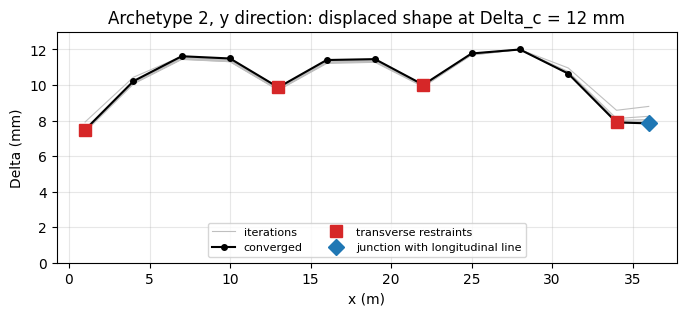

,x (m),point,m (t),Delta (mm),restraint force (N),secant k (N/mm)
DOF,,,,,,
0,1.0,transverse restraint,0.2496,7.4821,4489.2399,600.0000
1,4.0,hanger,0.3743,10.2178,NaN,NaN
2,7.0,hanger,0.3743,11.6204,NaN,NaN
3,10.0,hanger,0.3743,11.4944,NaN,NaN
4,13.0,transverse restraint,0.3743,9.8693,5921.5895,600.0000
5,16.0,hanger,0.3743,11.4075,NaN,NaN
6,19.0,hanger,0.3743,11.4575,NaN,NaN
7,22.0,transverse restraint,0.3743,10.0127,6005.4240,599.7833
8,25.0,hanger,0.3743,11.7752,NaN,NaN


In [11]:
Delta = DELTA_C * d
lp = load_pattern(Delta)
kind = np.array(["hanger"] * rs.n_hangers + ["junction"], dtype=object)
kind[idx_T] = "transverse restraint"
shape = pd.DataFrame({"x (m)": x_dof / 1000, "point": kind, "m (t)": m_dof, "Delta (mm)": Delta})
shape.loc[idx_T, "restraint force (N)"] = lp["F_T"]
shape.loc[idx_T, "secant k (N/mm)"] = lp["k_T"]
shape.loc[rs.n_dof - 1, "restraint force (N)"] = lp["V_L_tot"]
shape.loc[rs.n_dof - 1, "secant k (N/mm)"] = lp["V_L_tot"] / Delta[-1]
shape.index.name = "DOF"

fig, ax = plt.subplots(figsize=(8, 3))
for k, s in enumerate(shapes[1:-1], start=1):
    ax.plot(x_dof / 1000, DELTA_C * s, color="0.75", lw=0.8, label="iterations" if k == 1 else None)
ax.plot(x_dof / 1000, Delta, "k-o", ms=4, label="converged")
ax.plot(x_dof[idx_T] / 1000, Delta[idx_T], "s", color="C3", ms=8, label="transverse restraints")
ax.plot(x_dof[-1] / 1000, Delta[-1], "D", color="C0", ms=8, label="junction with longitudinal line")
ax.set(xlabel="x (m)", ylabel="Delta (mm)", ylim=(0, 13), title="Archetype 2, y direction: displaced shape at Delta_c = 12 mm")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower center", ncol=2)
plt.show()
shape

## Phase 2: equivalent SDOF system (Section 3.2)

### Step 1: effective mass and equivalent displacement

$\mathbf{m}_{full}$ collects all masses (transverse line and longitudinal line) and $\boldsymbol{\Delta}_{full}$ their
displacements, with $\Delta_{L,1} = \Delta_{T|L,1}$. Then (Eqs. 9-10)

$m_{eff} = (\sum m_l \Delta_l)^2 / \sum m_l \Delta_l^2$, $\quad \Delta_D = \sum m_l \Delta_l^2 / \sum m_l \Delta_l$.

In [12]:
m_full = np.r_[m_dof, m_L]
D_full = np.r_[Delta, Delta[-1]]
S1, S2 = np.sum(m_full * D_full), np.sum(m_full * D_full**2)
m_eff = S1**2 / S2                       # Eq. 9
Delta_D = S2 / S1                        # Eq. 10
print(f"sum m*Delta = {S1:.4f} t mm;  sum m*Delta^2 = {S2:.4f} t mm2")
print(f"m_eff   = {m_eff:.4f} t  ({m_eff / m_full.sum():.1%} of the total {m_full.sum():.4f} t)")
print(f"Delta_D = {Delta_D:.3f} mm")

sum m*Delta = 64.2836 t mm;  sum m*Delta^2 = 638.3405 t mm2
m_eff   = 6.4736 t  (97.0% of the total 6.6755 t)
Delta_D = 9.930 mm


### Step 2: non-linear model of the SDOF

Each restraint's force-displacement law is moved to SDOF coordinates with Eq. 11,
$\tilde V_l(\Delta) = V_l(\Delta\,\Delta_l/\Delta_D)$: its deformations are divided by $\Delta_l/\Delta_D$ and its forces are
unchanged. The SDOF spring is the sum of the transformed restraints in parallel.

The transformation is applied to the restraint's hysteretic model, a Pinching4 material whose envelope has four
points (the static procedure of Phase 1 used its trilinear idealisation through points 2 and 3). Only the envelope
deformations change; the cyclic parameters are ratios and stay as they are. The longitudinal line's spring
carries the forces of its two restraints.

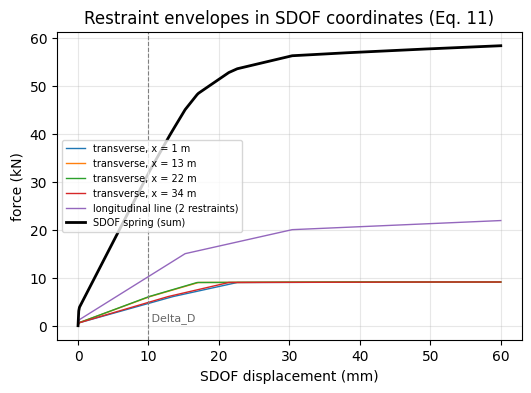

,Delta_l (mm),Delta_l / Delta_D,d1 (mm),F1 (N),d2 (mm),F2 (N),d3 (mm),F3 (N),d4 (mm),F4 (N)
restraint,,,,,,,,,,
"transverse, x = 1 m",7.4821,0.7535,0.1327,600.0,13.2718,6000.0,22.5621,9000.0,47.7786,9100.0
"transverse, x = 13 m",9.8693,0.9939,0.1006,600.0,10.0616,6000.0,17.1047,9000.0,36.2216,9100.0
"transverse, x = 22 m",10.0127,1.0083,0.0992,600.0,9.9175,6000.0,16.8598,9000.0,35.7031,9100.0
"transverse, x = 34 m",7.8953,0.7951,0.1258,600.0,12.5771,6000.0,21.3811,9000.0,45.2777,9100.0
longitudinal line (2 restraints),7.8420,0.7897,0.1266,1200.0,15.1953,15000.0,30.3905,20000.0,77.2426,23000.0


In [13]:
supports = [(f"transverse, x = {x_dof[i] / 1000:g} m", Delta[i], 1, rs.transverse) for i in idx_T]
supports.append((f"longitudinal line ({n_L} restraints)", Delta[-1], n_L, rs.longitudinal))
rows = []
for name, D_l, n, p4 in supports:
    r = D_l / Delta_D
    row = {"restraint": name, "Delta_l (mm)": D_l, "Delta_l / Delta_D": r}
    for k in range(4):
        row[f"d{k + 1} (mm)"] = p4.pos_disp[k] / r
        row[f"F{k + 1} (N)"] = n * p4.pos_force[k]
    rows.append(row)
springs = pd.DataFrame(rows).set_index("restraint")

def envelope(p4, n, ratio, u):
    # piecewise-linear Pinching4 envelope in SDOF coordinates (Eq. 11), flat beyond the last point
    return np.interp(u, np.r_[0.0, np.array(p4.pos_disp) / ratio], n * np.r_[0.0, p4.pos_force])

u = np.linspace(0, 60, 601)
fig, ax = plt.subplots(figsize=(6, 4))
total = np.zeros_like(u)
for name, D_l, n, p4 in supports:
    f = envelope(p4, n, D_l / Delta_D, u)
    total += f
    ax.plot(u, f / 1000, lw=1, label=name)
ax.plot(u, total / 1000, "k", lw=2, label="SDOF spring (sum)")
ax.axvline(Delta_D, color="0.5", ls="--", lw=0.8)
ax.text(Delta_D, 1, " Delta_D", color="0.4", fontsize=8)
ax.set(xlabel="SDOF displacement (mm)", ylabel="force (kN)", title="Restraint envelopes in SDOF coordinates (Eq. 11)")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()
springs

**Equivalent SDOF system.** Mass $m_{eff}$, displacement $\Delta_D$, spring as above. In the repository's SDOF files
(`piperom sdof`) the same transformation is written with the participation factor $\Gamma$ and the shape $\phi$
normalised at the longitudinal line: $\Delta_l/\Delta_D = \Gamma\,\phi_l$.

In [14]:
phi = Delta / Delta[-1]
Gamma = np.sum(m_full * np.r_[phi, phi[-1]]) / np.sum(m_full * np.r_[phi, phi[-1]]**2)
print(f"Gamma = {Gamma:.4f};  Gamma * phi_l = Delta_l / Delta_D: "
      f"{np.allclose(Gamma * phi[idx_T], Delta[idx_T] / Delta_D)}")
pd.Series({"m_eff (t)": m_eff, "Delta_D (mm)": Delta_D, "Gamma": Gamma,
           "SDOF spring force at Delta_D (N)": np.interp(Delta_D, u, total)}).to_frame("equivalent SDOF")

Gamma = 0.7897;  Gamma * phi_l = Delta_l / Delta_D: True


,equivalent SDOF
m_eff (t),6.4736
Delta_D (mm),9.9301
Gamma,0.7897
SDOF spring force at Delta_D (N),31589.3666


## Check against `piperom`

`piperom sdof` runs the same procedure (`derive_sdof`) and writes the SDOF springs used in the time histories.
Its $\Gamma$, $m_{eff}$ and $\Delta_D$ are computed from the shape of the last solve, one iteration before the
converged shape used above, so they, and its spring envelopes, differ from the values above by about 0.2%.
With its default settings (those of the paper's results), the SDOF is derived at the pushover step
closest to 12 mm (12.32 mm) and its values are rounded to 3 decimals; at this target the restraints are still
nearly elastic, so the shape, and therefore the SDOF, is practically the same.

In [15]:
from dataclasses import replace
from piperom.sdof import derive_sdof

exact = derive_sdof(rs, replace(settings, sdof_on_pushover_grid=False, sdof_round_decimals=None), DELTA_C)
paper = derive_sdof(rs, settings)
cmp = pd.DataFrame({
    "this notebook": [DELTA_C, m_eff, Delta_D, Gamma],
    "piperom, 12 mm": [exact.delta_c, exact.effective_mass, exact.u_sdof, exact.gamma],
    "piperom defaults (paper)": [paper.delta_c, paper.effective_mass, paper.u_sdof, paper.gamma],
}, index=["Delta_c (mm)", "m_eff (t)", "Delta_D (mm)", "Gamma"])
assert np.isclose(exact.effective_mass, m_eff, rtol=5e-3) and np.isclose(exact.gamma, Gamma, rtol=5e-3)
d_engine = np.array([s.spring.pos_disp for s in exact.supports])
assert np.allclose(d_engine, springs[[f"d{k} (mm)" for k in range(1, 5)]].to_numpy(), rtol=5e-3)
display(cmp)
print("Gamma*phi at the restraints, piperom defaults:", np.round([paper.gamma * s.phi for s in paper.supports], 3))
print("Delta_l / Delta_D, this notebook:            ", np.round(np.r_[Delta[idx_T], Delta[-1]] / Delta_D, 3))

,this notebook,"piperom, 12 mm",piperom defaults (paper)
Delta_c (mm),12.0000,12.0000,12.320
m_eff (t),6.4736,6.4753,6.473
Delta_D (mm),9.9301,9.9128,10.180
Gamma,0.7897,0.7911,0.790


Gamma*phi at the restraints, piperom defaults: [0.754 0.997 1.014 0.796 0.79 ]
Delta_l / Delta_D, this notebook:             [0.753 0.994 1.008 0.795 0.79 ]
